
## Supervised Learning Models in Practice


**Submission Format:** Single Jupyter Notebook (`.ipynb`)

---
## 📌 General Instructions (Read Carefully)

- This assignment covers **Modules 13–18**.
- Use **Python and scikit-learn only**.
- Do NOT use AutoML, deep learning, or external ML libraries.
- Fix `random_state=42` wherever applicable.
- Plots must be labeled and readable.
- Do not delete or rename cells.

***Classification Dataset:*** https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data/data

***Regresssion Dataset:*** https://www.kaggle.com/datasets/mirichoi0218/insurance

## 🔧 TODO 0: Environment Setup (5 Marks)
**Marks Breakdown:**
- Correct imports (3)
- Clean setup, no unused imports (2)


In [ ]:
# TODO: Import all necessary libraries here
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score, precision_score,recall_score,f1_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR,SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

plt.style.use('default')
sns.set(font_scale=1.1)

# 🔵 PART A: Regression Task (45 Marks)
You will work with the provided **regression dataset**.


## TODO A1: Dataset Loading and Understanding (5 Marks)
**You must:**
- Load the dataset
- Show shape and column names
- Identify target variable

**Marks:** Data loading (2), Explanation (3)


In [ ]:
# TODO: Load regression dataset
insurance='/content/sample_data/insurance.csv'
df_in=pd.read_csv(insurance)
print('shape',df_in.shape)
target_col_in= 'charges'
df_in.columns

shape (1338, 7)


Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [ ]:
df_in.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


The insurance dataset contains 1,338 rows and 7 columns: age, sex, bmi, children, smoker, region and charges. The target variable is charges (medical insurance cost billed to an individual). Since it is a continuous numerical value, this is a regression problem. There are no missing values in the dataset.

## TODO A2: Exploratory Data Analysis (EDA) (5 Marks)
**You must:**
- Show descriptive statistics
- Plot correlation heatmap
- Plot at least one feature vs target

**Marks:** Plots (3), Interpretation (2)


In [ ]:
# TODO: Perform EDA
cat_cols_in = df_in.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols_in =[c for c in df_in.select_dtypes(include=[np.number]).columns if c !=target_col_in]

df_in.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [ ]:
df_in.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


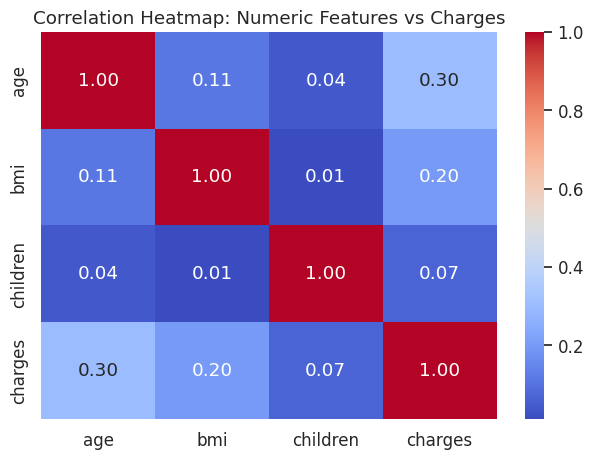

In [ ]:
#heatmap
corr_matrix=df_in[num_cols_in+[target_col_in]].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap: Numeric Features vs Charges')
plt.tight_layout()
plt.show()

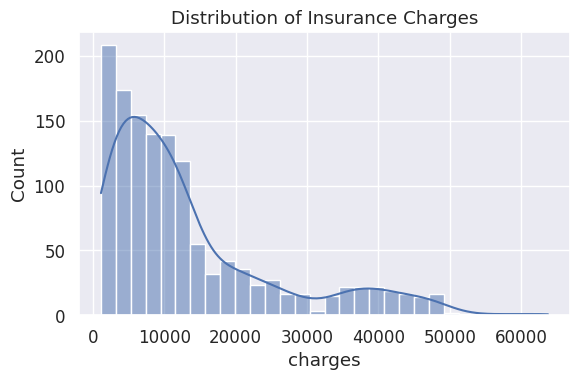

In [ ]:
# Distribution of the target
plt.figure(figsize=(6, 4))
sns.histplot(df_in[target_col_in], bins=30, kde=True)
plt.title('Distribution of Insurance Charges')
plt.xlabel('charges')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

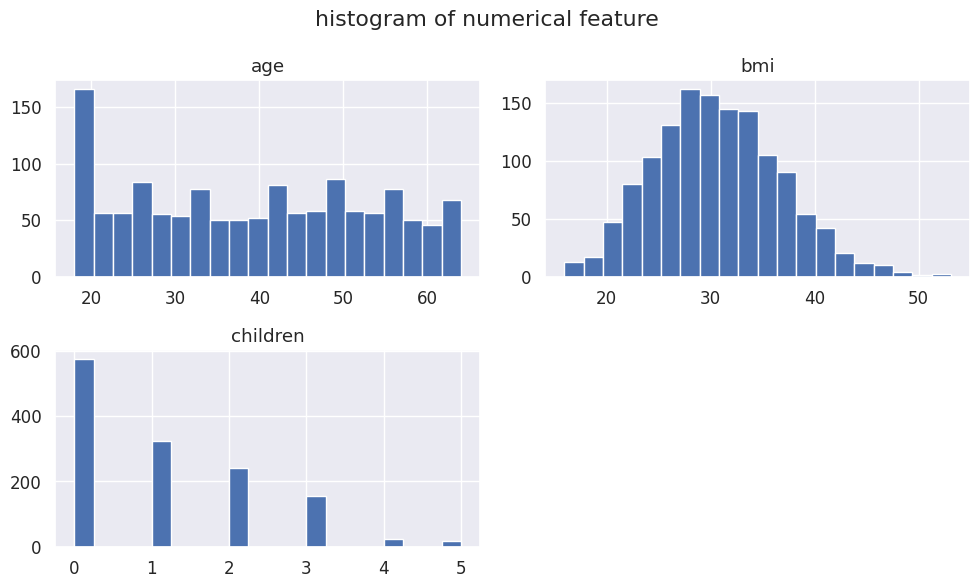

In [ ]:
#histogrms
df_in[num_cols_in].hist(bins=20,figsize=(10,6))
plt.suptitle('histogram of numerical feature ')
plt.tight_layout()
plt.show()

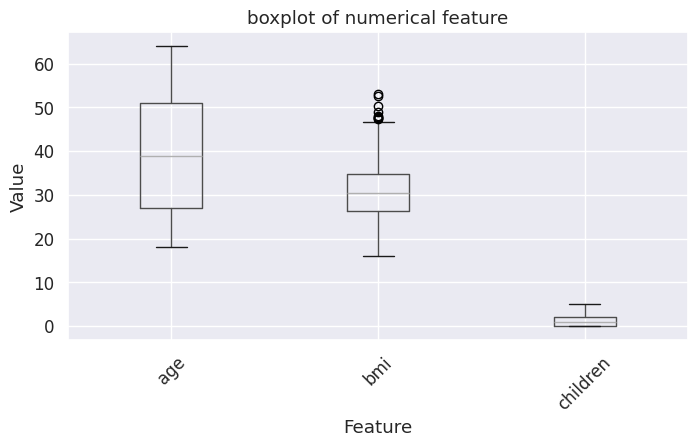

In [ ]:

plt.figure(figsize=(8,4))
df_in[num_cols_in].boxplot()
plt.title('boxplot of numerical feature')
plt.xlabel('Feature')
plt.ylabel('Value')
plt.xticks(rotation=45)
plt.show()

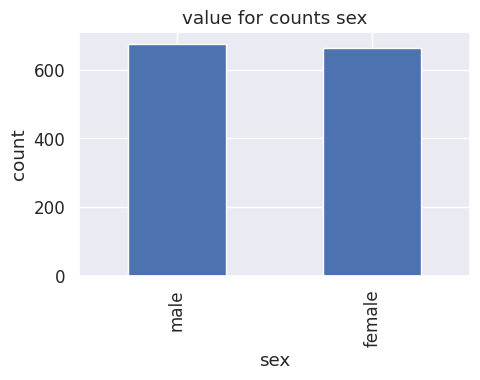

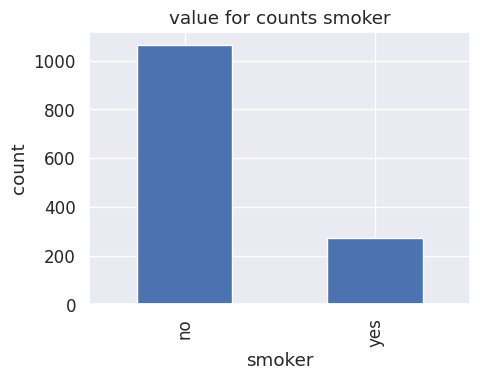

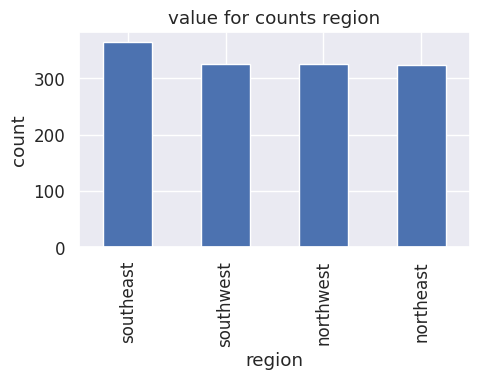

In [ ]:
for c in cat_cols_in:
  plt.figure(figsize=(5,4))
  df_in[c].value_counts().plot(kind='bar')
  plt.title(f'value for counts {c}')
  plt.ylabel('count')
  plt.tight_layout()
  plt.show()

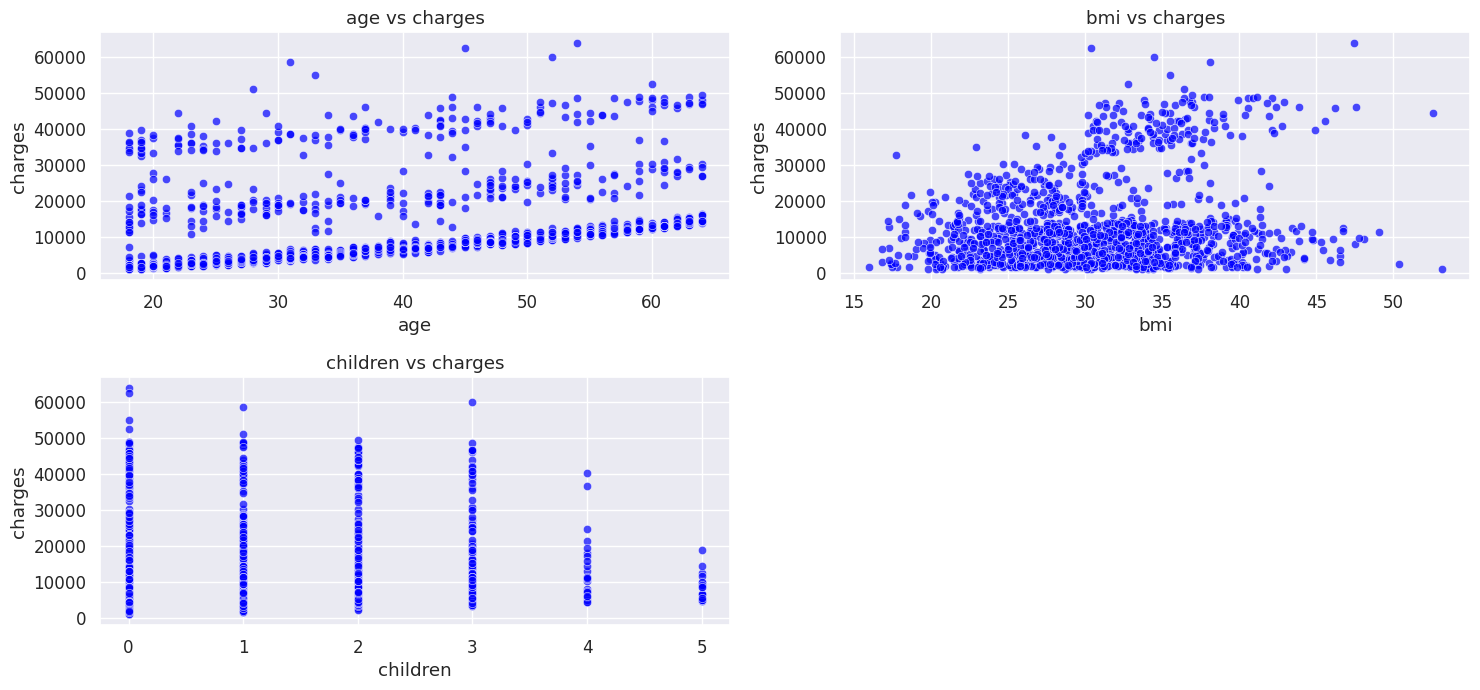

In [ ]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols_in, 1):
    plt.subplot(3, 2, i)
    sns.scatterplot(x=df_in[col], y=df_in['charges'], alpha=0.7, color='blue')
    plt.title(f'{col} vs charges')
    plt.xlabel(col)
    plt.ylabel('charges')

plt.tight_layout()
plt.show()

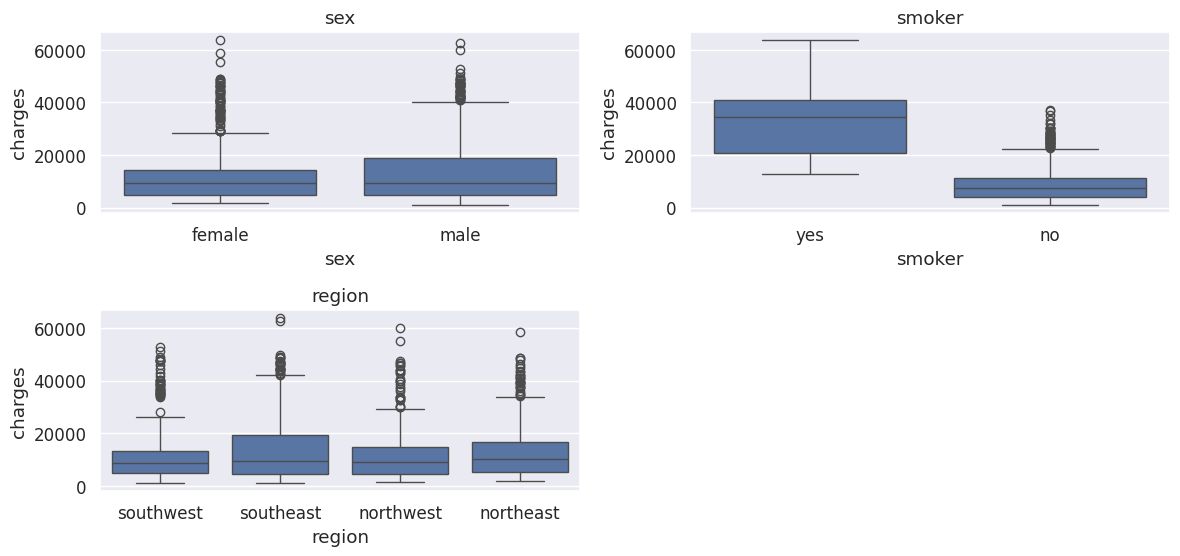

In [ ]:
plt.figure(figsize=(12,8))
for i, col in enumerate(cat_cols_in,1):
  plt.subplot(3, 2, i)
  sns.boxplot(x=df_in[col],y=df_in[target_col_in])
  plt.title(col)
plt.tight_layout()
plt.show()


- The correlation heatmap shows that age and bmi have a positive correlation with charges, with age being the stronger of the two. The children feature has only a weak relationship.
- The distribution of charges is right-skewed, meaning most people have low-to-moderate costs while a few have very high costs.
- The scatter plots and boxplots show that smokers have much higher charges than non-smokers, which makes smoker one of the most influential features. Charges also tend to increase with age.

## TODO A3: Feature Preparation (5 Marks)
**You must:**
- Train-test split
- Scaling (if applicable)

**Marks:** Correct split (3), Explanation (2)


In [ ]:
# TODO: Prepare features
X = pd.get_dummies(df_in.drop(columns=target_col_in), drop_first=True,dtype=int)
y=df_in[target_col_in]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scale= StandardScaler()
X_train_scale=scale.fit_transform(X_train)
X_test_scale=scale.transform(X_test)

The categorical columns (sex, smoker, region) were converted to numeric form using one-hot encoding with drop_first=True to avoid multicollinearity. The data was split into 75% training and 25% testing sets with random_state=42. StandardScaler was fitted on the training data only and then applied to the test data. Scaling is important for distance-based and margin-based models such as SVR and for polynomial features.
StandardScaler was fitted on the training data only and then applied to the test data, which prevents data leakage from the test set into training. Scaling is important for distance-based and margin-based models such as SVR and for polynomial features.

## TODO A4: Multiple Linear Regression (8 Marks)
**You must:**
- Train model
- Evaluate using RMSE, MAE, R²

**Marks:** Model (4), Metrics (4)


In [ ]:
# TODO: Multiple Linear Regression
mlr=LinearRegression()
mlr.fit(X_train_scale, y_train)

y_pred=mlr.predict(X_test_scale)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mean_squared_error(y_test,y_pred))
r2=r2_score(y_test,y_pred)

print('Mae:',mae)
print('Rmse:',rmse)
print('R2:',r2)

Mae: 4243.654116653148
Rmse: 5926.023602394469
R2: 0.7672642952734356


Multiple Linear Regression achieved MAE of about 4243.65, RMSE of about 5926.02 and R2 of about 0.767. It is a good baseline, but it assumes a purely linear relationship, which limits its performance on this data.

## TODO A5: Polynomial Regression (7 Marks)
**You must:**
- Apply polynomial features
- Compare with linear regression

**Marks:** Implementation (4), Comparison (3)


In [ ]:
# TODO: Polynomial Regression
model = Pipeline([
  ('poly', PolynomialFeatures(degree=2, include_bias=False)),
  ('lin_reg', LinearRegression())
])

model.fit(X_train_scale,y_train)
y_pred_p=model.predict(X_test_scale)

mae=mean_absolute_error(y_test,y_pred_p)
rmse=np.sqrt(mean_squared_error(y_test,y_pred_p))
r2=r2_score(y_test,y_pred_p)

print('Mae:',mae)
print('Rmse:',rmse)
print('R2:',r2)

Mae: 2781.7101811019197
Rmse: 4689.452858277404
R2: 0.854259380947993


Polynomial Regression (degree = 2) achieved MAE of about 2781.71, RMSE of about 4689.45 and R2 of about 0.854. Compared with Linear Regression (MAE of about 4243.65, RMSE of about 5926.02, R2 of about 0.767), the error dropped significantly and R2 improved by about 0.09. This shows that the relationship between the features and charges is non-linear, and that interactions between features (for example, smoking combined with BMI) matter. The trade-off is a higher risk of overfitting as the degree increases.

## TODO A6: Support Vector Regression (7 Marks)
**You must:**
- Train SVR (RBF kernel)
- Evaluate performance
- Justify kernel choice

**Marks:** Model (4), Justification (3)


In [ ]:
# TODO: Support Vector Regression
rbf= SVR(kernel='rbf', C=100.0,epsilon= 0.1, gamma='scale')
rbf.fit(X_train_scale,y_train)
y_pred_rbf=rbf.predict(X_test_scale)

In [ ]:
mae=mean_absolute_error(y_test,y_pred_rbf)
rmse=np.sqrt(mean_squared_error(y_test,y_pred_rbf))
r2=r2_score(y_test,y_pred_rbf)

print('Mae:',mae)
print('Rmse:',rmse)
print('R2:',r2)

Mae: 6013.844851943568
Rmse: 11036.151553011146
R2: 0.19281780666843296


Kernel justification: The RBF kernel was chosen because the relationship between the features and charges is non-linear, as the polynomial regression result showed. The RBF kernel can capture such non-linear patterns without manually creating polynomial features.
SVR is sensitive to the scale of the target variable. Since charges has very large values, SVR on the raw target performed poorly (R2 of about 0.19).

## TODO A7: Random Forest Regressor (8 Marks)
**You must:**
- Train Random Forest
- Evaluate model

**Marks:** Model (4), Evaluation (4)


In [ ]:
# TODO: Random Forest Regressor
param_grid = {
    "n_estimators": [100, 150, 175, 200],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 3, 5],
}
rf = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
rf.fit(X_train_scale, y_train)

In [ ]:
best_rf_model = rf.best_estimator_
y_pred_rf = best_rf_model.predict(X_test_scale)

mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

The Random Forest Regressor was tuned with GridSearchCV (5-fold cross-validation) over n_estimators, max_depth and min_samples_split. It achieved MAE of about 2632.17, RMSE of about 4592.53 and R2 of about 0.860, the best result among all regression models. Random Forest can capture non-linear relationships and feature interactions automatically, and it is robust to outliers.

# 🟠 PART B: Classification Task (45 Marks)
You will work with the provided **classification dataset**.


## TODO B1: Dataset Understanding (5 Marks)
**You must:**
- Load dataset
- Show class distribution
- Comment on imbalance

**Marks:** Analysis (3), Explanation (2)


In [ ]:
# TODO: Load classification dataset
loan='/content/sample_data/loan_data.csv'
df_loan=pd.read_csv(loan)
target_col='loan_status'
print('class distribution:',df_loan[target_col].value_counts())

The dataset is imbalanced. Class 0 has a significantly higher number of samples (35,000, about 77.8%) compared to Class 1 (10,000, about 22.2%). This means the model might become biased towards the majority class (0). Because of this, accuracy alone is misleading, so Precision, Recall, F1-Score (or ROC-AUC) should also be used for evaluation.


In [ ]:
df_loan.nunique()

In [ ]:
df_loan.isnull().sum()

In [ ]:
cat_cols = df_loan.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols =[c for c in df_loan.select_dtypes(include=[np.number]).columns if c != target_col]

target_Col='loan_status'
print(df_loan.shape)
print(cat_cols)
print(num_cols)
print(df_loan.info())
df_loan.head()

In [ ]:
df_loan.describe().T

## TODO B2: Exploratory Data Analysis (5 Marks)
**You must:**
- Plot class counts
- Plot at least one feature vs class

**Marks:** Plots (5),


In [ ]:
# TODO: Classification EDA
plt.figure(figsize=(5,4))
sns.countplot(x=df_loan[target_Col])
plt.title('Class distribution of loan_status (0 = rejected, 1 = approved)')
plt.xlabel('loan_status')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


In [ ]:
#histogram num cols
df_loan[num_cols].hist(bins=20,figsize=(12,8))
plt.suptitle('Histograms of numerical features')
plt.tight_layout()
plt.show()

In [ ]:
#boxplot num cols
plt.figure(figsize=(12,8))
df_loan[num_cols].boxplot()
plt.title('Boxplot of numerical features')
plt.xlabel('Feature')
plt.ylabel('Value')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#cat cols plot
for c in cat_cols:
  plt.figure(figsize=(5,4))
  df_loan[c].value_counts().plot(kind='bar')
  plt.title(f'value for counts {c}')
  plt.tight_layout()
  plt.show()

In [ ]:
#plot cat cols and target
for c in cat_cols:
  ct=pd.crosstab(df_loan[c],df_loan[target_Col],normalize='index')
  print(f'\n Proportion of loan status {c}')
  display(ct)
  ct.plot(kind='bar',stacked=True, figsize=(6,4))
  plt.title(f'loan status proportion by {c}')
  plt.xticks(rotation=90)
  plt.tight_layout()
  plt.show()

In [ ]:
#boxplot target and numeric cols
plt.figure(figsize=(20, 15))

for i, col in enumerate(num_cols, 1):
    plt.subplot(6, 2, i)
    sns.boxplot(x=df_loan['loan_status'], y=df_loan[col])
    plt.title(col)
    plt.tight_layout()

plt.show()

The count plot confirms the class imbalance. The histograms and boxplots show that some numeric features such as person_age, person_emp_exp and person_income are skewed and contain outliers. The proportion plots for categorical features show that factors such as previous_loan_defaults_on_file and person_home_ownership are strongly related to the loan status, while the boxplots show that features like loan_int_rate and loan_percent_income differ clearly between the two classes.

## TODO B3: Feature Preparation (5 Marks)
**You must:**
- Encoding (if needed)
- Scaling
- Train-test split with stratification




In [ ]:
# Impossible values remove
df_loan = df_loan[(df_loan['person_age'] <= 80) & (df_loan['person_emp_exp'] <= 60)].reset_index(drop=True)
print('Rows after removing impossible values:', df_loan.shape[0])
# Income skewed > log transform
if df_loan['person_income'].max() > 100:
    df_loan['person_income'] = np.log(df_loan['person_income'])

In [ ]:
# TODO: Prepare classification features
X = df_loan.drop(columns=[target_Col])
y = df_loan[target_Col]

X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Scaling (income as it is)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Train:', X_train_scaled.shape, ' Test:', X_test_scaled.shape)

Rows with impossible values (age above 80 or work experience above 60 years) were removed. The skewed person_income feature was log-transformed. Categorical variables were one-hot encoded with drop_first=True. The data was split 80/20 with random_state=42 and stratify=y so that both sets keep the same class ratio. StandardScaler was fitted on the training set only. The final shapes are 35,992 training rows and 8,998 test rows.

## TODO B4: Logistic Regression with L2 (8 Marks)
**You must:**
- Train Logistic Regression
- Evaluate using Accuracy, Precision, Recall
- Show Confusion Matrix

**Marks:** Model (4), Metrics (4)


In [ ]:
# TODO: Logistic Regressio
lr=LogisticRegression(max_iter=100,C=1.0, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred=lr.predict(X_test_scaled)

print('Accuracy:',accuracy_score(y_test,y_pred))
print('Recall:',recall_score(y_test,y_pred))
print('Precision:',precision_score(y_test,y_pred))
print('F1 score :', f1_score(y_test, y_pred))

cm= confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d', cmap='Blues')
plt.title('Logistic Regression: Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.tight_layout()
plt.show()

Logistic Regression with L2 regularization (the default penalty) achieved Accuracy of about 0.900, Precision of about 0.783, Recall of about 0.763 and F1 of about 0.773. It is a simple, fast and interpretable baseline. The confusion matrix shows that it misses a number of actual approved loans (false negatives) because of the class imbalance and its linear decision boundary.

## TODO B5: Support Vector Machine (7 Marks)
**You must:**
- Train SVM (Linear or RBF)
- Evaluate

**Marks:** Model (4), Evaluation (3)


In [ ]:
# TODO: SVM Classification
svc_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svc_rbf.fit(X_train_scaled,y_train)
y_pred_rbf=svc_rbf.predict(X_test_scaled)

In [ ]:
print('Accuracy:',accuracy_score(y_test,y_pred_rbf))
print('Recall:',recall_score(y_test,y_pred_rbf))
print('Precision:',precision_score(y_test,y_pred_rbf))
print('f1 score:',f1_score(y_test,y_pred_rbf))
cm_rbf= confusion_matrix(y_test,y_pred_rbf)
print('Confusion matrix:\n',cm_rbf)

The RBF SVM reached accuracy of about 0.917, precision of about 0.854, recall of about 0.758 and F1 of about 0.803.

Kernel justification: the RBF kernel was chosen because loan approval depends on several features at once (for example income, interest rate and loan-to-income ratio), so the classes are unlikely to be separated by a straight line. RBF can learn a non-linear boundary.

Compared with Logistic Regression (accuracy 0.900, precision 0.783, recall 0.763, F1 0.773), the RBF SVM is better in accuracy, precision and F1, while recall is almost the same (slightly lower). This suggests the decision boundary is not perfectly linear.


## TODO B6: Naive Bayes (5 Marks)
**You must:**
- Choose correct NB variant



In [ ]:
# TODO: Naive Bayes
nv=GaussianNB()
nv.fit(X_train_scaled,y_train)
y_pred_nv=nv.predict(X_test_scaled)
print('Accuracy:',accuracy_score(y_test,y_pred_nv))
print('Recall:',recall_score(y_test,y_pred_nv))
print('Precision:',precision_score(y_test,y_pred_nv))
print('f1 score:',f1_score(y_test,y_pred_nv))
cm_nv= confusion_matrix(y_test,y_pred_nv)
print('Confusion matrix:\n',cm_nv)

Variant choice: GaussianNB was chosen because the numeric features are continuous (and were standardised). MultinomialNB needs non-negative count-like features, which standardised data does not satisfy, and BernoulliNB needs binary features, so Gaussian is the correct variant here.

Gaussian Naive Bayes had accuracy of about 0.745 with very high recall (about 0.984) but low precision (about 0.465). It finds almost every approved loan, but it also approves a lot of loans it should not, probably because its independence assumption does not fit this data.


## TODO B7: K-Nearest Neighbors (5 Marks)
**You must:**
- Try multiple K values
- Plot accuracy vs K

**Marks:** Experiment (3), Plot & choice (2)


In [ ]:
# TODO: KNN
k_values = range(1, 42)
accs = []

for k in k_values:
    kn=KNeighborsClassifier(n_neighbors=k, metric="minkowski", p=2)
    kn.fit(X_train_scaled, y_train)
    y_pred_kn = kn.predict(X_test_scaled)
    accs.append(accuracy_score(y_test, y_pred_kn))

In [ ]:
plt.figure()
plt.plot(list(k_values), accs)
plt.xlabel("K (n_neighbors)")
plt.ylabel("Accuracy")
plt.title(" Accuracy vs K (scaled)")
plt.show()

best_k = list(k_values)[int(np.argmax(accs))]
print("Best K :", best_k)
print("Best accuracy:", float(np.max(accs)))

Accuracy changes with K, and the best value was K = 23 with accuracy of about 0.903. Very small K overfits and very large K underfits. Ideally K should be chosen using cross-validation rather than the test set.

## TODO B8: Random Forest Classifier (5 Marks)
**You must:**
- Train model
- Show feature importance

**Marks:** Model (3), Interpretation (2)


In [ ]:
# TODO: Random Forest Classifier
#Baseline Random Forest Model
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_baseline.fit(X_train, y_train)
y_pred_rf = rf_baseline.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("F1 score:", f1_score(y_test, y_pred_rf))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_rf))

In [ ]:
#Feature Importance
importances = pd.Series(
    rf_baseline.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importances.head(10)

In [ ]:
#Visualisation
plt.figure(figsize=(8,5))
importances.head(10).plot(kind="bar")
plt.title("Top 10 Feature Importances")
plt.xlabel("Feature")
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()

The Random Forest reached an accuracy of about 0.928, the highest accuracy among all classification models I tried. Its precision, recall, F1-score and confusion matrix are printed above, so it can be compared fairly with the RBF SVM on this imbalanced data.


The most important feature is previous_loan_defaults_on_file_Yes (about 0.22), followed by loan_percent_income (about 0.16), loan_int_rate (about 0.16) and person_income (about 0.13). This makes sense in real life: past defaults, a large loan compared to income and a high interest rate all signal higher risk.

# 🧠 Final Reflection (5 Marks)
**Answer briefly:**
- Best regression model and why
- Best classification model and why
- One real-world deployment scenario


## TODO: Write your reflection here

Best Regression Model: Random Forest Regressor, with R2 of about 0.86, RMSE of about 4592 and MAE of about 2632. It outperformed Linear Regression (R2 of about 0.77) and Polynomial Regression (R2 of about 0.85) because it captures non-linear relationships and feature interactions (such as smoker status combined with BMI and age) automatically.

Best Classification Model: Random Forest Classifier, with an accuracy of about 92.8%, closely followed by the RBF SVM (accuracy of about 91.7%, precision of about 85%). Because the data is imbalanced, precision, recall and F1-score were also checked, not just accuracy. Gaussian Naive Bayes had very high recall but low precision, so it is less reliable for decisions.

Real-world Deployment Scenario: A bank or fintech company could use the classification model for initial loan screening, automatically approving clearly good applicants and flagging borderline cases for review by a human loan officer. Similarly, an insurance company could use the regression model to estimate expected medical costs and set premiums. In both cases the models should be monitored for data drift and checked for fairness before being used in production.